## **Recovery versus electrode sparsity**

How much of the skin surface has to be instrumented before the seven parameters — five
tissue conductivities and the two inner interface radii — stop being recoverable from
noisy surface potentials. One synthetic dataset is generated at full coverage, and the
same data is then read through progressively sparser electrode arrays; each array gets
its own inversion from the same starting point, so the only thing that varies down the
sweep is how many readings the misfit is summed over.

There is no regularisation. A Tikhonov penalty would bias exactly the parameters this
experiment is trying to characterise — the weakly-determined ones — and pull the sparse
end of the sweep back towards the prior, which is the failure the sweep is meant to
expose. Everything computational is imported from `neuralphysics`.

In [1]:
# the API this experiment needs

import platform
import time

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import scipy
import torch
from scipy.optimize import minimize

import neuralphysics
from neuralphysics import (
    LIMB,
    SOURCE_SPECS,
    CoefficientHierarchy,
    ElectrodeArray,
    Observation,
    add_measurement_noise,
    configure,
    forward,
    gaussian_dipole,
    grid_at,
    interfaces_from_logits,
    lateral_surface_mask,
    levels,
    logits_from_interfaces,
    viz,
)

In [2]:
print(configure())
print(f"neuralphysics {neuralphysics.__version__} | torch {torch.__version__} | "
      f"numpy {np.__version__} | scipy {scipy.__version__} | python {platform.python_version()}")
print(f"default dtype {torch.get_default_dtype()} | torch threads {torch.get_num_threads()} | "
      f"{platform.platform()}")

{'dtype': 'torch.float64', 'seed': 42}
neuralphysics 0.1.0 | torch 2.5.1 | numpy 1.26.4 | scipy 1.17.1 | python 3.11.15
default dtype torch.float64 | torch threads 4 | macOS-26.6.1-arm64-arm-64bit


In [3]:
# the experiment
# anything not named here is at the package default
# L = 1, z_zeta = 1, coarsening floor of 9, jacobi damping factor omega = 2/3, nu = (2, 2),
# 50 base iterations, and the LIMB interface width epsilon

N = 65             # nodes per axis; N = 2^k + 1 must hold for the v-cycle to work
NUM_CYCLES = 8     # fixed budget - not a convergence tolerance
NOISE_PERCENT = 5.0  # surface electrode measurement noise, as a percentage of the clean field's RMS
NOISE_SEED = 0
WIDTH = 0.05       # the 1/e dipole blob radius, a physical length

# the inverse problem, started away from the truth

# bone 8 mm and muscle 11.5 mm against the true values of 7 and 13,
# which leaves fat at 3.5 mm against a true value of 3
# outermost radius is absent because we assume skin thickness to be known - so not recovered
RADII_INIT = (8.0 / 48.0, 19.5 / 48.0)

SIGMA_INIT = {"bone": 0.05, "muscle_T": 0.05, "muscle_L": 0.20, "fat": 0.02, "skin": 0.10}

MAX_ITERS = 1000   # L-BFGS-B iteration budget, per array

# scipy's tolerances are calibrated for O(1) objectives. Here J ~ 1e-5 and
# ||grad J|| ~ 5e-6 near the solution, so the default gtol = 1e-5 is already satisfied
# at the starting point and L-BFGS-B would return after one evaluation having done
# nothing. ftol is relative to max(|f|, 1) = 1, so it is effectively absolute, and the
# default 2.2e-9 would stop while the misfit is still moving in the fourth digit.
FTOL = 1e-16
GTOL = 1e-12

LIMB_RADIUS_MM = 24.0   # the physical limb radius, at r/R = 0.5

In [4]:
print(f"grid     N = {N}, levels {levels(N)}")
print(f"solver   {NUM_CYCLES} V-cycles")
print(f"data     {NOISE_PERCENT}% noise (seed {NOISE_SEED})")
print(f"inverse  L-BFGS-B, <= {MAX_ITERS} iterations, ftol {FTOL:g}, gtol {GTOL:g}, "
      f"no penalty")

grid     N = 65, levels [65, 33, 17, 9]
solver   8 V-cycles
data     5.0% noise (seed 0)
inverse  L-BFGS-B, <= 1000 iterations, ftol 1e-16, gtol 1e-12, no penalty


In [5]:
grid = grid_at(N)

# two fibre-aligned Gaussian dipoles inside muscle, one deep and one shallow. The pair
# differ in radius, not angle: the limb is rotationally symmetric, so two blobs at one
# radius are rotated copies carrying the same information.
sources = [gaussian_dipole(grid, LIMB, width=WIDTH, r_blob_norm=r, angle_deg=a)
           for r, a in SOURCE_SPECS]

coeff_true = CoefficientHierarchy.from_vectors(LIMB, N)

print(grid)
print(f"sources at r/R = {[r for r, _ in SOURCE_SPECS]}, "
      f"peaks {[round(float(I.abs().max()), 4) for I in sources]}")
print(f"det(J)   min {float(grid.det_J.min()):.5f}, max {float(grid.det_J.max()):.5f}")

CylinderGrid(n=65, L=1.0, smoothing=SmoothingPolicy(iterations=100, del_t=0.2), z_zeta=1.0, mapped=True)
sources at r/R = [0.25, 0.312], peaks [0.9893, 0.9871]
det(J)   min 0.11417, max 1.11886


In [6]:
# one dataset, generated once at full coverage; the sweep reads subsets of it, so
# every array in the sweep sees the same noise realisation rather than a fresh draw

mask_full = ElectrodeArray().mask(N)      # all four lateral faces

observations = []
for s, I in enumerate(sources):
    phi_s = forward(I, coeff_true, num_cycles=NUM_CYCLES)
    phi_obs, noise_stats = add_measurement_noise(phi_s, NOISE_PERCENT, NOISE_SEED + s)
    observations.append(Observation(phi=phi_obs, mask=mask_full, grid=grid))
    print(f"noise  source {s}: {NOISE_PERCENT:.1f}% of RMS {noise_stats['rms']:.3e} -> "
          f"std {noise_stats['noise_std']:.3e}, realised SNR {noise_stats['snr']:.2f}")

print(f"array  {int(mask_full.sum())} electrodes of {N ** 3} nodes at full coverage")

noise  source 0: 5.0% of RMS 6.926e-04 -> std 3.463e-05, realised SNR 20.00
noise  source 1: 5.0% of RMS 7.093e-04 -> std 3.546e-05, realised SNR 20.02
array  16640 electrodes of 274625 nodes at full coverage


In [7]:
param_names = list(SIGMA_INIT)
sigma_true = torch.tensor([LIMB.sigma_layers["bone"][0],
                           LIMB.sigma_layers["muscle"][0],
                           LIMB.sigma_layers["muscle"][1],
                           LIMB.sigma_layers["fat"][0],
                           LIMB.sigma_layers["skin"][0]])
rho_ref = torch.log(torch.tensor([SIGMA_INIT[nm] for nm in param_names]))

n_sigma = len(param_names)
R_OUTER = LIMB.interfaces[-1]          # fat/skin surface: fixed, not recovered

theta_ref = torch.cat([rho_ref, logits_from_interfaces(RADII_INIT + (R_OUTER,))])
theta_true = torch.cat([torch.log(sigma_true), logits_from_interfaces(LIMB.interfaces)])


def unpack(theta):
    """(7,) parameters -> (sigma_T, sigma_L, interface radii).

    The first five are log-conductivities. bone, fat and skin appear in both vectors as
    the same tensor element, so an isotropic tissue's gradient accumulates into one
    scalar; muscle splits into T and L.

    The last two are softmax logits for the two inner interfaces. They are
    unconstrained: any real pair gives 0 < R_1 < R_2 < R_OUTER, so L-BFGS-B needs no
    bounds and no ordering constraint.
    """
    s = theta[:n_sigma].exp()
    return (torch.stack([s[0], s[1], s[3], s[4]]),      # bone, muscle_T, fat, skin
            torch.stack([s[0], s[2], s[3], s[4]]),      # bone, muscle_L, fat, skin
            interfaces_from_logits(theta[n_sigma:], R_OUTER))


def thicknesses_mm(interfaces):
    """Interface radii -> the four layer thicknesses in mm, skin closed off at the rim.

    A thickness is the anatomical quantity; a radius is a coordinate. Skin appears here
    even though it is not recovered, because it is the difference between R_OUTER and
    the rim and so is the one thickness fixed by assumption.
    """
    R = torch.as_tensor(interfaces).reshape(-1)
    edges = torch.cat([torch.zeros_like(R[:1]), R, torch.full_like(R[:1], 0.5)])
    return torch.diff(edges) * (LIMB_RADIUS_MM / 0.5)


sT_ref, sL_ref = LIMB.sigma_vectors()
sT_chk, sL_chk, R_chk = unpack(theta_true)
print(f"layers {LIMB.layer_names} | params {param_names} + logits u_1, u_2")
print(f"unpack(theta_true) reproduces the tissue table: "
      f"{torch.allclose(sT_chk, sT_ref) and torch.allclose(sL_chk, sL_ref)}")
print(f"          and round-trips the geometry: "
      f"{torch.allclose(R_chk, torch.as_tensor(LIMB.interfaces))}")
print(f"start sigma {[f'{v:.3f}' for v in rho_ref.exp().tolist()]}")
print(f"start  {[f'{v:.2f}' for v in thicknesses_mm(unpack(theta_ref)[2]).tolist()]} mm")
print(f"true   {[f'{v:.2f}' for v in thicknesses_mm(LIMB.interfaces).tolist()]} mm")

layers ('bone', 'muscle', 'fat', 'skin') | params ['bone', 'muscle_T', 'muscle_L', 'fat', 'skin'] + logits u_1, u_2
unpack(theta_true) reproduces the tissue table: True
          and round-trips the geometry: True
start sigma ['0.050', '0.050', '0.200', '0.020', '0.100']
start  ['8.00', '11.50', '3.50', '1.00'] mm
true   ['7.00', '13.00', '3.00', '1.00'] mm


The sweep is over node strides on the lateral faces, not over `ElectrodeArray`'s single
coverage target: the stride there is isotropic and quantised to $1/s^2$, so it jumps
from 100% to 25% with nothing in between. Two strides — one around the rim, one along
the limb — halve the coverage at each step instead.

In [8]:
def stride_mask(n, s_ang, s_z):
    """Lateral-surface electrodes on a (s_ang, s_z) node stride: s_ang around the rim,
    s_z along the limb. Separate strides because halving one gives coverage a factor of
    two, which a single isotropic stride cannot -- ceil(1/sqrt(0.5)) = 2 jumps straight
    from 100% to 25%."""
    face = torch.zeros(n, n, dtype=torch.bool)
    face[::s_ang, ::s_z] = True
    m = torch.zeros(n, n, n, dtype=torch.bool)
    m[0] |= face
    m[-1] |= face
    m[:, 0] |= face
    m[:, -1] |= face
    return m


STRIDES = [(1, 1), (1, 2), (2, 2), (2, 4), (4, 4), (4, 8)]
surf = lateral_surface_mask(N)

for s in STRIDES:
    m = stride_mask(N, *s)
    print(f"stride {s}: {int(m.sum()):6d} electrodes, "
          f"coverage {int((m & surf).sum()) / int(surf.sum()):.3f}")

stride (1, 1):  16640 electrodes, coverage 1.000
stride (1, 2):   8448 electrodes, coverage 0.508
stride (2, 2):   4224 electrodes, coverage 0.254
stride (2, 4):   2176 electrodes, coverage 0.131
stride (4, 4):   1088 electrodes, coverage 0.065
stride (4, 8):    576 electrodes, coverage 0.035


In [9]:
def run_inversion(mask):
    """Invert against the data read through `mask`.

    The objective is the data misfit alone -- no penalty term -- so what the sparse
    arrays recover is what the readings themselves determine.

    Returns (recovered sigma, recovered interface radii, result).
    """
    n_eval = [0]

    def objective(theta_np):
        theta = torch.tensor(theta_np, dtype=torch.float64, requires_grad=True)
        sT_vec, sL_vec, R = unpack(theta)
        coeff = CoefficientHierarchy.from_vectors(LIMB, N, sT_vec, sL_vec, interfaces=R)
        preds = [forward(I, coeff, num_cycles=NUM_CYCLES) for I in sources]

        loss = sum(0.5 * ((p - o.phi)[mask] ** 2).sum()
                   for p, o in zip(preds, observations))
        loss.backward()

        n_eval[0] += 1
        return loss.item(), theta.grad.detach().numpy().copy()

    result = minimize(objective, theta_ref.numpy(), jac=True, method="L-BFGS-B",
                      options={"maxiter": MAX_ITERS, "maxfun": 4 * MAX_ITERS,
                               "ftol": FTOL, "gtol": GTOL})
    result.n_eval = n_eval[0]
    theta_hat = torch.tensor(result.x)
    return theta_hat[:n_sigma].exp(), unpack(theta_hat)[2], result

In [10]:
coverages, errors, thickness_errors = [], [], []
thick_true = thicknesses_mm(LIMB.interfaces)

for s in STRIDES:
    m = stride_mask(N, *s)
    cov = int((m & surf).sum()) / int(surf.sum())
    t0 = time.time()
    sigma_rec, R_rec, result = run_inversion(m)
    rel = ((sigma_rec - sigma_true).abs() / sigma_true).numpy()
    thick_rel = ((thicknesses_mm(R_rec) - thick_true).abs() / thick_true).numpy()
    coverages.append(cov)
    errors.append(rel)
    thickness_errors.append(thick_rel)
    print(f"coverage {cov:6.3f} ({int(m.sum()):6d} nodes, {result.n_eval:3d} evals, "
          f"{time.time() - t0:6.1f}s)  "
          + "  ".join(f"{nm} {e:6.2%}" for nm, e in zip(param_names, rel))
          + "  |  " + "  ".join(f"{nm} {e:6.2%}" for nm, e in zip(LIMB.layer_names, thick_rel)))

errors = np.array(errors)
thickness_errors = np.array(thickness_errors)

coverage  1.000 ( 16640 nodes, 121 evals,  558.0s)  bone  8.25%  muscle_T  0.23%  muscle_L  0.90%  fat  2.58%  skin  0.57%  |  bone  1.00%  muscle  0.90%  fat  1.58%  skin  0.00%
coverage  0.508 (  8448 nodes, 122 evals,  635.3s)  bone 11.11%  muscle_T  0.52%  muscle_L  0.99%  fat  8.95%  skin  4.84%  |  bone  0.62%  muscle  0.71%  fat  1.60%  skin  0.00%
coverage  0.254 (  4224 nodes, 138 evals,  615.4s)  bone 20.12%  muscle_T  2.07%  muscle_L  2.45%  fat 25.11%  skin 15.06%  |  bone  1.51%  muscle  1.72%  fat  3.93%  skin  0.00%
coverage  0.131 (  2176 nodes, 119 evals,  581.4s)  bone 15.61%  muscle_T  3.17%  muscle_L  3.10%  fat 37.38%  skin 20.81%  |  bone  0.48%  muscle  1.34%  fat  4.70%  skin  0.00%
coverage  0.065 (  1088 nodes, 123 evals,  596.1s)  bone 10.83%  muscle_T  2.43%  muscle_L  0.83%  fat 39.96%  skin 30.13%  |  bone  4.83%  muscle  2.32%  fat  1.22%  skin  0.00%
coverage  0.035 (   576 nodes, 115 evals,  578.0s)  bone 10.11%  muscle_T  3.19%  muscle_L  1.16%  fat 41

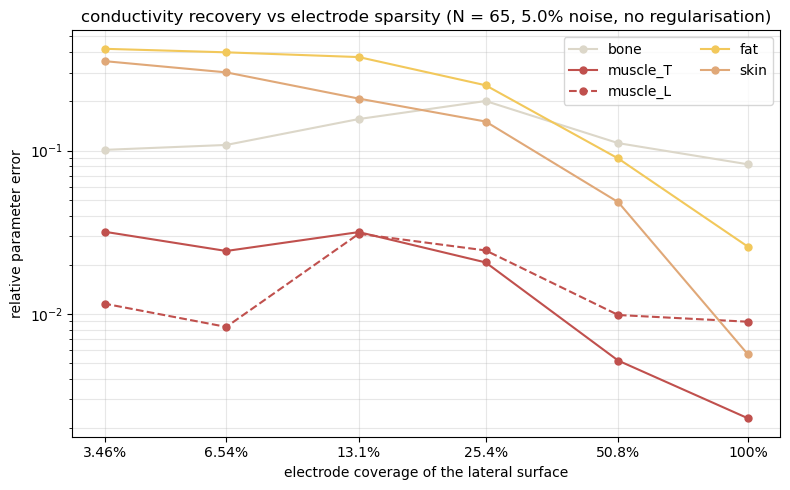

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))

for k, nm in enumerate(param_names):
    colour, ls = viz.PARAM_STYLE[nm]
    ax.loglog(np.array(coverages) * 100, errors[:, k], color=colour, ls=ls,
              marker="o", ms=5, label=nm)

ticks = np.array(coverages) * 100
ax.set_xticks(ticks, minor=False)
ax.set_xticks([], minor=True)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.3g}%"))

ax.set_xlabel("electrode coverage of the lateral surface")
ax.set_ylabel("relative parameter error")
ax.set_title(f"conductivity recovery vs electrode sparsity "
             f"(N = {N}, {NOISE_PERCENT:.1f}% noise, no regularisation)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(ncol=2)
fig.tight_layout()

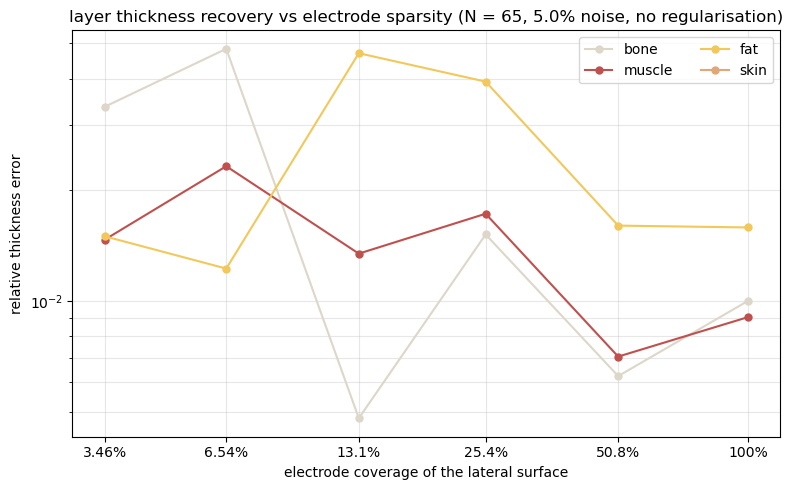

In [12]:
fig_thick, ax_thick = plt.subplots(figsize=(8, 5))

for k, nm in enumerate(LIMB.layer_names):
    ax_thick.loglog(np.array(coverages) * 100, thickness_errors[:, k],
                    color=viz.TISSUE_COLOURS[nm], marker="o", ms=5, label=nm)

ticks = np.array(coverages) * 100
ax_thick.set_xticks(ticks, minor=False)
ax_thick.set_xticks([], minor=True)
ax_thick.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.3g}%"))

ax_thick.set_xlabel("electrode coverage of the lateral surface")
ax_thick.set_ylabel("relative thickness error")
ax_thick.set_title(f"layer thickness recovery vs electrode sparsity "
                   f"(N = {N}, {NOISE_PERCENT:.1f}% noise, no regularisation)")
ax_thick.grid(True, which="both", alpha=0.3)
ax_thick.legend(ncol=2)
fig_thick.tight_layout()